# FSAI, Inc. — DIA Phase 3: Visualization Portfolio
Generates every chart in the Phase 3 portfolio, deck and final report from the **Phase 1** and **Phase 2** outputs. Nothing is hand-entered.

**Inputs** (place both zips next to this notebook, or set the folder variables):
- `FSAI_DIA_Phase1_outputs.zip` → `phase1_outputs/`
- `FSAI_DIA_Phase2_outputs.zip` → `phase2_outputs/`

**Output:** `portfolio/` with PNG figures V01–V15, and `portfolio_numbers.json` holding every number quoted in the captions.

In [1]:
import importlib, subprocess, sys
for pkg, mod in [("geopandas","geopandas"), ("pyogrio","pyogrio"), ("mlxtend","mlxtend"), ("scikit-learn","sklearn")]:
    try: importlib.import_module(mod)
    except ImportError: subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
import os, json, zipfile, shutil, warnings
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd, joblib
import matplotlib.pyplot as plt, matplotlib.gridspec as gridspec, seaborn as sns
from matplotlib.patches import Patch
from scipy import stats
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, precision_recall_curve, average_precision_score
from mlxtend.frequent_patterns import apriori, association_rules
warnings.filterwarnings("ignore")

P1 = Path(os.environ.get("DIA_PHASE1_DIR", "phase1_outputs")); P2 = Path(os.environ.get("DIA_PHASE2_DIR", "phase2_outputs"))
for d, z in [(P1, "FSAI_DIA_Phase1_outputs.zip"), (P2, "FSAI_DIA_Phase2_outputs.zip")]:
    if not d.exists() and Path(z).exists():
        with zipfile.ZipFile(z) as f: f.extractall(d)
OUT = Path("portfolio"); OUT.mkdir(exist_ok=True)

INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8984", "#e6e6e3"
BLUE, ORANGE, GREEN, GOLD, PINK = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
SEQ3 = ["#86b6ef", "#2a78d6", "#104281"]
CLUSTER_COL = {"C1": "#86b6ef", "C2": ORANGE, "C3": "#104281"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6, "font.size": 10, "axes.edgecolor": MUTED,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left", "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2})
NUM = {}
def save(name):
    plt.savefig(OUT/f"{name}.png", bbox_inches="tight", facecolor="white"); plt.show(); plt.close()

In [2]:
# ---------- Load ----------
p1 = json.loads((P1/"run_summary.json").read_text())
L = pd.read_csv(P2/"lgu_features_corrected.csv", index_col=0)
A = joblib.load(P2/"model_artifacts.pkl")
LOG = pd.read_csv(P2/"experiment_log.csv")
rain = pd.read_csv(P1/"clean/rainfall_daily_clean.csv", parse_dates=["date"])
bounds = gpd.read_file(P1/"clean/dia_lgu_boundaries.geojson")
L["cluster"] = L.index.map(A["lgu_kmeans"]["labels"])
REPS = [g[0] for g in p1["power_cell_groups"]]; rep_of = {n: g[0] for g in p1["power_cell_groups"] for n in g}

# ---------- Rebuild the Phase 2 daily table (same code path as model_pipeline.ipynb) ----------
THR = pd.Series(A["daily_extreme_classifier"]["extreme_thresholds_mm"])
D = rain[rain.lgu_name.isin(REPS)].sort_values(["lgu_name", "date"]).reset_index(drop=True); D["cell"] = D.lgu_name
g = D.groupby("cell")
D["extreme_today"] = (D.PRECTOTCORR >= D.cell.map(THR)).astype(int)
D["y_next_extreme"] = g.extreme_today.shift(-1)
D["rain_next3_mm"] = g.PRECTOTCORR.transform(lambda s: s[::-1].rolling(3, min_periods=3).sum()[::-1].shift(-1))
D["rh_change"] = g.RH2M.diff(); D["rain_lag1"] = g.PRECTOTCORR.shift(1)
D = D.dropna(subset=["y_next_extreme", "rain_next3_mm", "rain_30d_mm", "rh_change", "rain_lag1"]).reset_index(drop=True)
D["y_next_extreme"] = D.y_next_extreme.astype(int); D["year"] = D.date.dt.year
for c in REPS: D[f"cell_{c.replace(' ', '_')}"] = (D.cell == c).astype(int)
hold = D[D.year >= 2021].reset_index(drop=True)
FAM = A["daily_classifiers_all_families"]
for a, d in FAM.items(): hold[f"p_{a}"] = d["model"].predict_proba(hold[d["features"]])[:, 1]
print("hold-out rows", len(hold), "extreme", hold.y_next_extreme.sum())

hold-out rows 6387 extreme 223


## V01 — Study area and 100-year flood hazard

In [3]:
f100 = gpd.read_file(P1/"clean/dia_hazard_web_flood_100yr.geojson")
fig, ax = plt.subplots(figsize=(6.2, 9))
bounds.plot(ax=ax, color="#f4f3ef", edgecolor="#c9c8c3", lw=.7)
for lvl, c, lab in zip([1, 2, 3], SEQ3, ["Low (≤0.5 m)", "Medium (0.5–1.5 m)", "High (>1.5 m)"]):
    f100[f100.hazard_level == lvl].plot(ax=ax, color=c, lw=0)
for _, r in bounds.iterrows():
    p = r.geometry.representative_point(); ax.annotate(r.lgu_name, (p.x, p.y), fontsize=7.5, ha="center", color=INK)
ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(SEQ3, ["Low (≤0.5 m)", "Medium (0.5–1.5 m)", "High (>1.5 m)"])],
          title="Flood depth class", frameon=False, loc="lower left", fontsize=8)
ax.set_axis_off(); ax.set_title("Zambales + Olongapo: NOAH 100-year flood hazard", loc="left")
save("V01_study_area_flood100")
NUM["area_km2"] = p1["aoi_area_km2"]

## V02 — Map coverage gap (5/25-yr vs 100-yr)

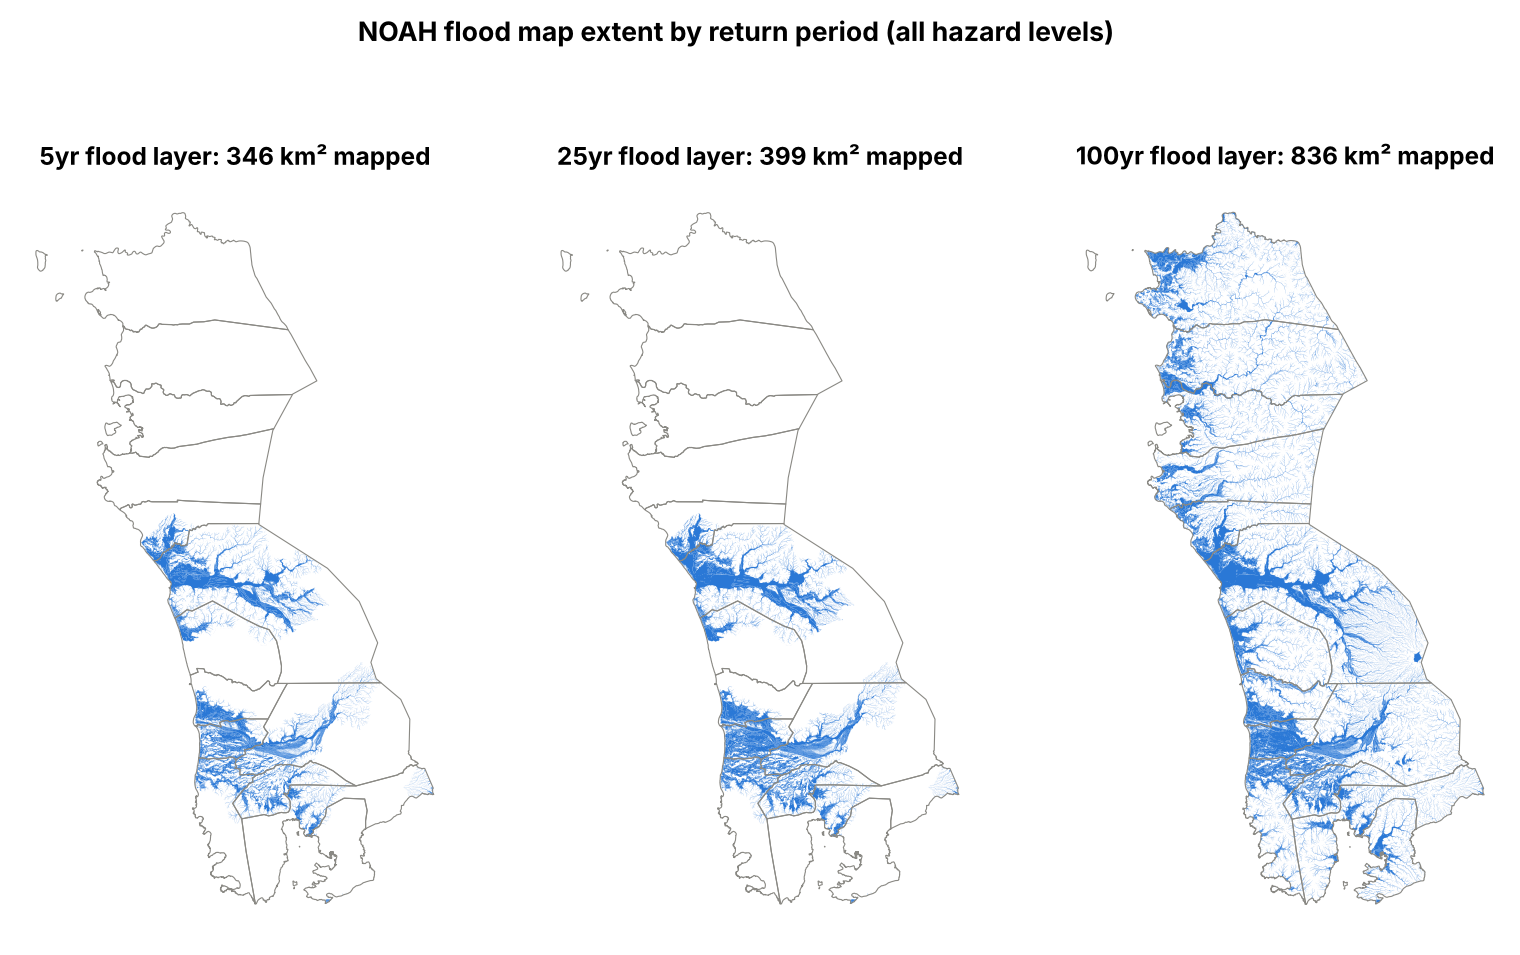

In [4]:
shutil.copy(P1/"figures/09_flood_extent_by_scenario.png", OUT/"V02_coverage_gap.png")
NUM["unmapped_5_25"] = L.index[~L.mapped_5_25yr].tolist()
from IPython.display import Image, display; display(Image(OUT/"V02_coverage_gap.png", width=700))

## V03 — How much worse in a rare storm? (dumbbell, corrected shares)

In [5]:
M = L[L.mapped_5_25yr].sort_values("flood_100yr_high_pct")
fig, ax = plt.subplots(figsize=(8, 5.2))
y = np.arange(len(M))
ax.hlines(y, M.flood_5yr_high_pct, M.flood_100yr_high_pct, color=GRID, lw=4, zorder=1)
ax.scatter(M.flood_5yr_high_pct, y, s=70, color=SEQ3[0], zorder=2, label="5-year", edgecolor="white", lw=1.5)
ax.scatter(M.flood_100yr_high_pct, y, s=70, color=SEQ3[2], zorder=3, label="100-year", edgecolor="white", lw=1.5)
for i, (n, r) in enumerate(M.iterrows()):
    ax.text(r.flood_100yr_high_pct + .3, i, f"+{r.flood_100yr_high_pct - r.flood_5yr_high_pct:.1f} pp", va="center", fontsize=8, color=INK2)
ax.set_yticks(y, M.index); ax.set_xlabel("% of LGU land in HIGH flood hazard (>1.5 m)")
ax.set_title("High-hazard land roughly triples from the 5- to the 100-year event")
ax.legend(frameon=False, loc="lower right"); ax.grid(axis="y", visible=False)
fig.text(.01, -.02, "Excludes Candelaria, Masinloc, Palauig, Santa Cruz (no 5-yr NOAH map). Overlapping classes resolved.", fontsize=7.5, color=MUTED, transform=fig.transFigure)
save("V03_dumbbell_5_vs_100")
H1 = A["hypothesis_tests"]["H1_mapped_10"]; NUM["H1"] = H1

## V04 — Multi-hazard exposure heatmap (LGU × scenario)

In [6]:
cols = {"flood_5yr_any_pct": "Flood 5-yr", "flood_25yr_any_pct": "Flood 25-yr", "flood_100yr_any_pct": "Flood 100-yr",
        "flood_100yr_high_pct": "100-yr HIGH", "ss_ssa1_any_pct": "Surge SSA1", "ss_ssa2_any_pct": "Surge SSA2",
        "ss_ssa3_any_pct": "Surge SSA3", "ss_ssa4_any_pct": "Surge SSA4"}
H = L.sort_values(["cluster", "flood_100yr_any_pct"], ascending=[False, False])[list(cols)].rename(columns=cols)
mask = pd.DataFrame(False, index=H.index, columns=H.columns)
for n in H.index:
    if not L.loc[n, "mapped_5_25yr"]: mask.loc[n, ["Flood 5-yr", "Flood 25-yr"]] = True
fig, ax = plt.subplots(figsize=(9.5, 6.5))
sns.heatmap(H, mask=mask, cmap="Blues", annot=True, fmt=".1f", linewidths=2, linecolor="white", cbar_kws={"label": "% of LGU land", "shrink": .7}, ax=ax, annot_kws={"size": 8})
for (i, n) in enumerate(H.index):
    for j, c in enumerate(H.columns):
        if mask.loc[n, c]: ax.text(j + .5, i + .5, "not\nmapped", ha="center", va="center", fontsize=6.5, color=MUTED)
ax.set_yticklabels([f"{n}  [{L.loc[n, 'cluster']}]" for n in H.index], rotation=0); ax.set_ylabel(""); ax.grid(False)
ax.set_title("Exposure matrix: where flood and storm surge overlap")
save("V04_exposure_heatmap")

## V05 — Rainfall seasonality (Type I climate)

In [7]:
reg = rain[rain.lgu_name.isin(REPS)].pivot(index="date", columns="lgu_name", values="PRECTOTCORR").mean(axis=1)
mon = reg.resample("MS").sum(min_count=25).dropna().to_frame("mm"); mon["month"] = mon.index.month
fig, ax = plt.subplots(figsize=(9, 4))
ax.axvspan(3.5, 9.5, color="#eaf2fc", zorder=0); ax.text(6.5, mon.mm.max()*.97, "Wet season (May–Oct)", ha="center", color=BLUE, fontsize=9)
sns.boxplot(mon, x="month", y="mm", color=SEQ3[1], fliersize=2, linewidth=.8, ax=ax, boxprops={"alpha": .85})
ax.set_xticks(range(12), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_xlabel(""); ax.set_ylabel("Monthly rainfall (mm)")
H2 = A["hypothesis_tests"]["H2"]; NUM["H2"] = H2
ax.set_title(f"92% of rain falls May–Oct: median wet month {H2['median_wet_mm']:.0f} mm vs dry {H2['median_dry_mm']:.0f} mm")
save("V05_rainfall_seasonality")

## V06 — Extreme rain is getting heavier (annual max 1-day, Sen's slope)

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.2))
H3 = A["hypothesis_tests"]["H3"]; NUM["H3"] = H3
for c, col in zip(REPS, [BLUE, ORANGE, GREEN]):
    s = rain[rain.lgu_name == c].set_index("date").PRECTOTCORR; yy = s.groupby(s.index.year)
    am = yy.max()[yy.count() >= 360]
    sl = stats.theilslopes(am.values, am.index)
    ax.plot(am.index, am.values, marker="o", ms=3, lw=1, color=col, alpha=.55)
    ax.plot(am.index, sl[1] + sl[0]*am.index, lw=2.5, color=col, label=f"{c} cell: +{H3[c]['sen_mm_per_decade']:.1f} mm/decade (p = {H3[c]['p_two_sided']:.3f})")
ax.set_ylabel("Wettest day of the year (mm)"); ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("The wettest day of the year is ~14–17 mm heavier per decade since 1981")
save("V06_extreme_rain_trend")

## V07 / V08 / V09 — Correlation, clusters, network (Phase 2 figures)

In [9]:
for src, dst in [("p2_01_lgu_spearman", "V07_correlation_heatmap"), ("p2_03_cluster_map", "V08_cluster_map"),
                 ("p2_04_similarity_network", "V09_similarity_network"), ("p2_05_daily_holdout", "V12b_pr_curves_confusion"),
                 ("p2_06_daily_importance", "V13b_feature_importance"), ("p2_02_kmeans_selection", "V08c_kmeans_selection")]:
    shutil.copy(P2/f"figures/{src}.png", OUT/f"{dst}.png")
# V08b cluster profiles
prof = L.groupby("cluster")[["flood_100yr_high_pct", "flood_100yr_any_pct", "ss_ssa4_any_pct"]].mean()
prof["n"] = L.groupby("cluster").size(); NUM["cluster_profiles"] = prof.round(2).to_dict("index")
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(3); w = .26
for i, (c, lab, col) in enumerate([("flood_100yr_high_pct", "100-yr HIGH flood", SEQ3[2]), ("flood_100yr_any_pct", "100-yr ANY flood", SEQ3[0]), ("ss_ssa4_any_pct", "Storm surge SSA4", ORANGE)]):
    b = ax.bar(x + (i-1)*w, prof[c], w*.92, color=col, label=lab)
    ax.bar_label(b, fmt="%.1f", fontsize=8, color=INK2, padding=2)
names = {"C1": "C1 Lower exposure", "C2": "C2 Inland floodplain", "C3": "C3 Coastal double exposure"}
ax.set_xticks(x, [f"{names[c]}\n({prof.loc[c, 'n']} LGUs)" for c in prof.index]); ax.set_ylabel("Mean % of LGU land")
ax.legend(frameon=False, fontsize=8); ax.grid(axis="x", visible=False); ax.set_title("Three exposure profiles (k-Means, k = 3, bootstrap ARI 0.83)")
save("V08b_cluster_profiles")

## V10 — Association rules: what precedes an extreme-rain day

In [10]:
def band(s, edges, labels): return pd.cut(s, edges, labels=labels, right=False).astype(str)
T = pd.DataFrame({"Wet season": D.season.eq("wet"), "Jul–Sep": D.month.isin([7, 8, 9]),
    **{f"Rain today {b} mm": band(D.PRECTOTCORR, [0, 1, 10, 30, 1e9], ["<1", "1-10", "10-30", "≥30"]).eq(b) for b in ["<1", "1-10", "10-30", "≥30"]},
    **{f"7-day rain {b} mm": band(D.rain_7d_mm, [0, 20, 100, 200, 1e9], ["<20", "20-100", "100-200", "≥200"]).eq(b) for b in ["<20", "20-100", "100-200", "≥200"]},
    "Humidity ≥88%": D.RH2M >= 88, "Extreme today": D.extreme_today.eq(1), "NEXT": D.y_next_extreme.eq(1)})
fi = apriori(T, min_support=0.002, use_colnames=True, max_len=4)
R = association_rules(fi, metric="confidence", min_threshold=0.05)
R = R[R.consequents.apply(lambda c: c == frozenset({"NEXT"}))].copy()
R["rule"] = R.antecedents.apply(lambda s: " + ".join(sorted(s)))
# keep the most informative distinct rules: best lift, then add simple 1-item rules for contrast
top = R.sort_values("lift", ascending=False).drop_duplicates("rule").head(6)
simple = R[R.antecedents.apply(len) == 1].sort_values("lift", ascending=False).head(4)
show = pd.concat([top, simple]).drop_duplicates("rule").sort_values("lift")
base = D.y_next_extreme.mean(); NUM["rules_base_rate"] = base; NUM["rules_top"] = top[["rule", "support", "confidence", "lift"]].round(3).to_dict("records")
fig, ax = plt.subplots(figsize=(9, 4.6))
b = ax.barh(show.rule, show.lift, color=[SEQ3[2] if len(a) > 1 else SEQ3[0] for a in show.antecedents])
for rect, conf in zip(b, show.confidence): ax.text(rect.get_width() + .2, rect.get_y() + rect.get_height()/2, f"conf {conf:.0%}", va="center", fontsize=8, color=INK2)
ax.axvline(1, color=MUTED, ls="--", lw=1); ax.set_xlabel(f"Lift (× the {base:.1%} base rate of a next-day extreme)")
ax.set_title("After an extreme monsoon day, tomorrow is ~16× more likely to be extreme"); ax.grid(axis="y", visible=False)
save("V10_association_rules")

## V11 — ROC curves (hold-out 2021–2026)

In [11]:
fig, ax = plt.subplots(figsize=(6.2, 5.6))
yt = hold.y_next_extreme
cols_ = {"Logistic regression": BLUE, "Linear Discriminant Analysis": GREEN, "Decision tree": GOLD, "MLP neural network": ORANGE}
roc = {}
for a, col in cols_.items():
    fpr, tpr, _ = roc_curve(yt, hold[f"p_{a}"]); roc[a] = roc_auc_score(yt, hold[f"p_{a}"])
    ax.plot(fpr, tpr, lw=2.5 if a == A["daily_extreme_classifier"]["algorithm"] else 1.6, color=col, label=f"{a} (AUC {roc[a]:.3f})" + ("  ← final" if a == A["daily_extreme_classifier"]["algorithm"] else ""))
# baselines
clim = D[D.year < 2021].groupby(["cell", "month"]).y_next_extreme.mean()
p_clim = pd.Series(list(zip(hold.cell, hold.month))).map(clim.to_dict()).to_numpy()
fpr, tpr, _ = roc_curve(yt, p_clim); roc["Climatology baseline"] = roc_auc_score(yt, p_clim)
ax.plot(fpr, tpr, lw=1.4, color=MUTED, ls="--", label=f"Climatology baseline (AUC {roc['Climatology baseline']:.3f})")
ax.plot([0, 1], [0, 1], color=GRID, lw=1)
fin = A["daily_extreme_classifier"]; yh = (hold[f"p_{fin['algorithm']}"] >= fin["decision_threshold"]).astype(int)
tn, fp, fn, tp = confusion_matrix(yt, yh).ravel()
ax.scatter([fp/(fp+tn)], [tp/(tp+fn)], s=80, color=BLUE, edgecolor="white", zorder=5)
ax.annotate(f"operating point\nrecall {tp/(tp+fn):.0%}, false-alarm rate {fp/(fp+tn):.1%}", (fp/(fp+tn), tp/(tp+fn)), xytext=(.25, .45), fontsize=8, color=INK2, arrowprops={"arrowstyle": "-", "color": MUTED})
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate (recall)"); ax.legend(frameon=False, fontsize=7.5, loc="lower right")
ax.set_title("ROC — next-day extreme rain, hold-out 2021–2026")
save("V11_roc_curves")
NUM["roc_auc_hold"] = roc; NUM["final_cm"] = {"TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}

## V12 — Confusion matrices for all four model families (hold-out, tuned thresholds)

In [12]:
fig, axs = plt.subplots(1, 4, figsize=(14, 3.6))
NUM["cms"] = {}
for ax, a in zip(axs, cols_):
    thr = FAM[a]["threshold"]; yh = (hold[f"p_{a}"] >= thr).astype(int); cm = confusion_matrix(yt, yh)
    NUM["cms"][a] = cm.tolist()
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 12},
                xticklabels=["pred: no", "pred: extreme"], yticklabels=["actual: no", "actual: extreme"], linewidths=2, linecolor="white")
    rec = cm[1, 1]/cm[1].sum(); prec = cm[1, 1]/cm[:, 1].sum()
    ax.set_title(f"{a.replace('Linear Discriminant Analysis', 'LDA').replace(' neural network', '')}\nrecall {rec:.2f} · precision {prec:.2f}", fontsize=10); ax.grid(False)
plt.suptitle("Hold-out confusion matrices (223 extreme vs 6,164 normal days)", x=.01, ha="left", fontweight="bold")
save("V12_confusion_matrices")

## V13 — Iterative tuning: CV PR-AUC across experiment rounds

In [13]:
d = LOG[(LOG.section == "predictive-daily") & LOG.validation.str.startswith("forward") & LOG.PR_AUC.notna()].copy()
d["family"] = d.algorithm.replace({"Climatology baseline (cell × month rate)": "Baseline", "Persistence baseline": "Baseline",
                                   "Linear Discriminant Analysis": "LDA", "MLP neural network": "MLP", "Logistic regression": "Logistic"})
order = ["Logistic", "LDA", "Decision tree", "MLP"]
fig, ax = plt.subplots(figsize=(10, 4.4))
famcol = {"Logistic": BLUE, "LDA": GREEN, "Decision tree": GOLD, "MLP": ORANGE}
xs = 0; ticks = []
for f in order:
    sub = d[d.family == f]
    for _, r in sub.iterrows():
        ax.bar(xs, r.PR_AUC, color=famcol[f], alpha=1 if r.run_id in ("LR3",) else .75, width=.8)
        ax.errorbar(xs, r.PR_AUC, yerr=r.PR_AUC_sd, color=INK2, lw=.8, capsize=2)
        ticks.append((xs, r.run_id)); xs += 1
    xs += .8
for _, r in d[d.family == "Baseline"].iterrows():
    ax.axhline(r.PR_AUC, color=MUTED, ls="--", lw=1); ax.text(xs - .5, r.PR_AUC + .006, r.algorithm.split(" (")[0], fontsize=7.5, color=MUTED, ha="right")
ax.set_xticks([t[0] for t in ticks], [t[1] for t in ticks], rotation=60, ha="right", fontsize=7.5)
ax.set_ylabel("Mean CV PR-AUC (±1 SD over 4 folds)"); ax.grid(axis="x", visible=False)
ax.set_ylim(0, .52)
ax.legend(handles=[Patch(color=famcol[f], label=f) for f in order], frameon=False, ncol=4, loc="upper right", fontsize=8)
ax.set_title(f"{len(d[d.family != 'Baseline'])} model runs: every family beats both baselines; logistic regression scores highest")
save("V13_iteration_pr_auc")

## V14 — Real event replay: August 2026 habagat (Botolan cell, incl. Olongapo)

In [14]:
fin = A["daily_extreme_classifier"]; cellO = rep_of["Olongapo"]
ev = hold[(hold.cell == cellO) & hold.date.between("2026-08-15", "2026-09-06")].copy()
ev["score"] = ev[f"p_{fin['algorithm']}"]; thrmm = THR[cellO]
fig, ax1 = plt.subplots(figsize=(10, 4.2))
ax1.bar(ev.date, ev.PRECTOTCORR, color=[SEQ3[2] if v >= thrmm else SEQ3[0] for v in ev.PRECTOTCORR], width=.8)
ax1.axhline(thrmm, color=SEQ3[2], ls=":", lw=1); ax1.text(pd.Timestamp("2026-08-21"), thrmm + 1.5, f"extreme-day threshold {thrmm:.1f} mm", fontsize=8, color=SEQ3[2])
ax1.set_ylabel("Daily rainfall (mm)")
ax2 = ax1.twinx(); ax2.grid(False)
# score plotted at t+1 (the day it is a forecast FOR)
ax2.plot(ev.date + pd.Timedelta(days=1), ev.score, color=ORANGE, lw=2, marker="o", ms=4)
ax2.axhline(fin["decision_threshold"], color=ORANGE, ls="--", lw=1); ax2.set_ylim(0, 1.05)
ax2.set_ylabel("Model warning score (issued the day before)", color=ORANGE); ax2.tick_params(axis="y", colors=ORANGE)
ax2.spines["right"].set_visible(True)
warn = ev[ev.score >= fin["decision_threshold"]]
for _, r in warn.iterrows(): ax2.annotate("⚠", (r.date + pd.Timedelta(days=1), r.score), xytext=(0, 6), textcoords="offset points", ha="center", color=ORANGE, fontsize=11)
ax1.set_title("Aug 2026 habagat replay: warnings came a day ahead for 17 and 29 Aug; 28 Aug was missed", fontsize=11.5)
ax1.legend(handles=[Patch(color=SEQ3[2], label="extreme day"), Patch(color=SEQ3[0], label="other day"),
                    plt.Line2D([], [], color=ORANGE, marker="o", label="warning score for that day (⚠ = above threshold)")],
           frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.22), ncol=3)
fig.autofmt_xdate()
save("V14_event_replay_aug2026")
NUM["event"] = ev[["date", "PRECTOTCORR", "score"]].assign(date=lambda x: x.date.dt.date.astype(str)).round(3).to_dict("records")

## V15 — Executive dashboard

In [15]:
fig = plt.figure(figsize=(16, 9)); gs = gridspec.GridSpec(3, 4, figure=fig, height_ratios=[.45, 1.6, 1.6], hspace=.42, wspace=.3, top=.9)
H1m = A["hypothesis_tests"]["H1_mapped_10"]; ho = fin["holdout_metrics"]
kpis = [("14 LGUs · 3,734 km²", "Zambales + Olongapo study area"),
        (f"+{H1m['median_diff_pp']:.1f} pp", "median rise in HIGH-hazard land, 5→100-yr"),
        (f"+{np.mean([v['sen_mm_per_decade'] for v in A['hypothesis_tests']['H3'].values()]):.0f} mm/decade", "trend in the wettest day of the year"),
        (f"{ho['recall']:.0%} recall · AUC {ho['ROC_AUC']:.2f}", "next-day extreme-rain model, 2021–26 hold-out")]
for i, (big, small) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i]); ax.axis("off")
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, color="#f4f3ef", zorder=0))
    ax.text(.05, .6, big, fontsize=19, fontweight="bold", color=INK, transform=ax.transAxes)
    ax.text(.05, .2, small, fontsize=9.5, color=INK2, transform=ax.transAxes)
# cluster map
ax = fig.add_subplot(gs[1:, 0]); m = bounds.merge(L[["cluster"]], left_on="lgu_name", right_index=True)
for c in ["C1", "C2", "C3"]: m[m.cluster == c].plot(ax=ax, color=CLUSTER_COL[c], edgecolor="white", lw=.7)
for _, r in m.iterrows():
    p = r.geometry.representative_point(); ax.annotate(r.lgu_name, (p.x, p.y), fontsize=6, ha="center")
ax.legend(handles=[Patch(color=CLUSTER_COL[c], label=names[c]) for c in ["C1", "C2", "C3"]], frameon=False, fontsize=7, loc="lower left")
ax.set_axis_off(); ax.set_title("Exposure clusters", fontsize=11)
# dumbbell mini
ax = fig.add_subplot(gs[1, 1:3]); Mm = L[L.mapped_5_25yr].sort_values("flood_100yr_high_pct", ascending=False)
ax.bar(np.arange(len(Mm)) - .2, Mm.flood_5yr_high_pct, .4, color=SEQ3[0], label="5-yr"); ax.bar(np.arange(len(Mm)) + .2, Mm.flood_100yr_high_pct, .4, color=SEQ3[2], label="100-yr")
ax.set_xticks(range(len(Mm)), Mm.index, rotation=30, ha="right", fontsize=7.5); ax.set_ylabel("% land HIGH hazard", fontsize=8)
ax.legend(frameon=False, fontsize=8); ax.grid(axis="x", visible=False); ax.set_title("High flood hazard by LGU (mapped LGUs)", fontsize=11)
# trend mini
ax = fig.add_subplot(gs[2, 1:3])
s = rain[rain.lgu_name == cellO].set_index("date").PRECTOTCORR; yy = s.groupby(s.index.year); am = yy.max()[yy.count() >= 360]; sl = stats.theilslopes(am.values, am.index)
ax.plot(am.index, am.values, marker="o", ms=3, color=BLUE, lw=1); ax.plot(am.index, sl[1] + sl[0]*am.index, color=BLUE, lw=2.5)
ax.set_ylabel("mm", fontsize=8); ax.set_title(f"Wettest day per year — Botolan/Olongapo cell (+{sl[0]*10:.1f} mm/decade)", fontsize=11)
# ROC mini
ax = fig.add_subplot(gs[1, 3]); fpr, tpr, _ = roc_curve(yt, hold[f"p_{fin['algorithm']}"])
ax.plot(fpr, tpr, color=BLUE, lw=2); ax.plot([0, 1], [0, 1], color=GRID); ax.set_title(f"ROC, final model (AUC {ho['ROC_AUC']:.2f})", fontsize=11)
ax.set_xlabel("FPR", fontsize=8); ax.set_ylabel("TPR", fontsize=8)
# CM mini
ax = fig.add_subplot(gs[2, 3]); cm = confusion_matrix(yt, (hold[f"p_{fin['algorithm']}"] >= fin["decision_threshold"]).astype(int))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=["no", "extreme"], yticklabels=["no", "extreme"], annot_kws={"size": 11}); ax.grid(False)
ax.set_title("Confusion matrix (hold-out)", fontsize=11); ax.set_xlabel("predicted", fontsize=8); ax.set_ylabel("actual", fontsize=8)
fig.suptitle("DIA — Disaster Intelligence Atlas · Executive dashboard", x=.01, ha="left", fontsize=15, fontweight="bold")
save("V15_executive_dashboard")

In [16]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple, np.ndarray)): return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)): return float(f"{float(o):.6g}")
    if isinstance(o, (np.integer,)): return int(o)
    return o
(OUT/"portfolio_numbers.json").write_text(json.dumps(clean(NUM), indent=1))
sorted(p.name for p in OUT.glob("*.png"))

['V01_study_area_flood100.png',
 'V02_coverage_gap.png',
 'V03_dumbbell_5_vs_100.png',
 'V04_exposure_heatmap.png',
 'V05_rainfall_seasonality.png',
 'V06_extreme_rain_trend.png',
 'V07_correlation_heatmap.png',
 'V08_cluster_map.png',
 'V08b_cluster_profiles.png',
 'V08c_kmeans_selection.png',
 'V09_similarity_network.png',
 'V10_association_rules.png',
 'V11_roc_curves.png',
 'V12_confusion_matrices.png',
 'V12b_pr_curves_confusion.png',
 'V13_iteration_pr_auc.png',
 'V13b_feature_importance.png',
 'V14_event_replay_aug2026.png',
 'V15_executive_dashboard.png']